# Lei de Brewster — análise experimental

Notebook para ajustar curvas de intensidade de polarização e estimar o ângulo de Brewster.

**Arquivo necessário:** `ANGLE-VOLTS.xlsx`. Essa planilha não estava presente no ZIP recebido e não foi incluída. Coloque o arquivo na mesma pasta deste notebook antes de executar as células seguintes. O código de upload específico do Google Colab foi removido para permitir o uso em Jupyter local.

Skipping block 'Unnamed: 2' due to empty data after cleaning.
Skipping block 'Unnamed: 4' due to empty data after cleaning.
Skipping block 'Unnamed: 8' due to empty data after cleaning.
Skipping block 'Unnamed: 10' due to empty data after cleaning.
Skipping block 'Unnamed: 14' due to empty data after cleaning.
Skipping block 'Unnamed: 16' as it does not contain both angle and intensity columns.


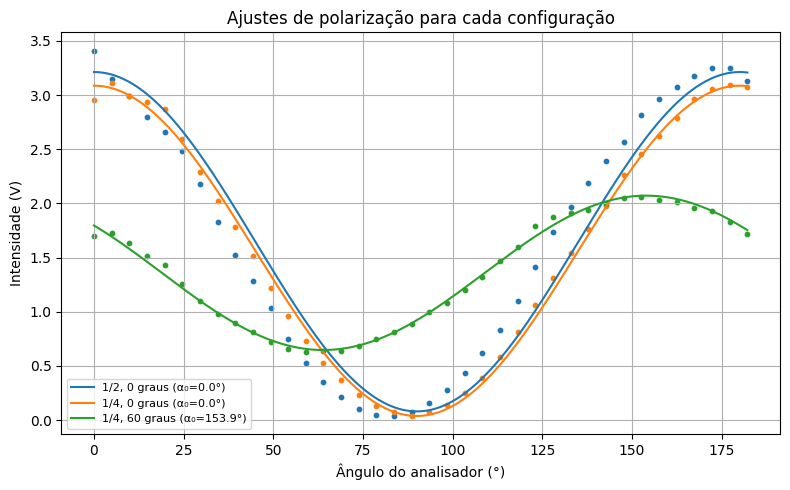


Resultados (direção de polarização α₀ para cada conjunto):
1/2, 0 graus         → α₀ ≈ 0.00°
1/4, 0 graus         → α₀ ≈ 0.00°
1/4, 60 graus        → α₀ ≈ 153.92°


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# === 1. Função modelo ===
def I_model(alpha_deg, A, B, alpha0_deg):
    alpha = np.deg2rad(alpha_deg)
    alpha0 = np.deg2rad(alpha0_deg)
    return A + B * np.cos(2 * (alpha - alpha0))

# === 2. Ler planilha ===
file_path = "ANGLE-VOLTS.xlsx"
df = pd.read_excel(file_path)

# === 3. Identificar blocos ===
colunas = df.columns
blocos = [colunas[i:i+2] for i in range(0, len(colunas), 2)]

resultados = []

plt.figure(figsize=(8,5))

# === 4. Loop pelos blocos ===
for bloco in blocos:
    nome = bloco[0]  # Exemplo: "1/2, 0 graus"
    data = df[bloco].copy() # Create a copy to avoid SettingWithCopyWarning

    # Check if the block has at least two columns
    if data.shape[1] < 2:
        print(f"Skipping block '{nome}' as it does not contain both angle and intensity columns.")
        continue

    # Skip the header row by starting from index 1
    alpha_exp_raw = data.iloc[1:,0]
    I_exp_raw = data.iloc[1:,1]

    # Convert data to numeric, coercing errors
    alpha_exp = pd.to_numeric(alpha_exp_raw, errors='coerce')
    I_exp = pd.to_numeric(I_exp_raw, errors='coerce')

    # Drop any rows that resulted in NaNs after coercion
    valid_indices = ~np.isnan(alpha_exp) & ~np.isnan(I_exp)
    alpha_exp = alpha_exp[valid_indices].to_numpy()
    I_exp = I_exp[valid_indices].to_numpy()

    # Check if arrays are empty after cleaning
    if len(alpha_exp) == 0 or len(I_exp) == 0:
        print(f"Skipping block '{nome}' due to empty data after cleaning.")
        continue


    A0 = np.mean(I_exp)
    B0 = (np.max(I_exp) - np.min(I_exp)) / 2
    alpha0_0 = alpha_exp[np.argmax(I_exp)]

    try:
        params, _ = curve_fit(I_model, alpha_exp, I_exp, p0=[A0, B0, alpha0_0],
                              bounds=([0,0,0], [np.inf, np.inf, 180]))
        A, B, alpha0 = params
        alpha0 = alpha0 % 180
        resultados.append((nome, alpha0))

        alpha_fit = np.linspace(min(alpha_exp), max(alpha_exp), 400)
        I_fit = I_model(alpha_fit, A, B, alpha0)
        plt.plot(alpha_fit, I_fit, label=f"{nome} (α₀={alpha0:.1f}°)")
        plt.scatter(alpha_exp, I_exp, s=10)
    except Exception as e:
        print(f"Erro ao ajustar {nome}: {e}")

plt.xlabel("Ângulo do analisador (°)")
plt.ylabel("Intensidade (V)")
plt.title("Ajustes de polarização para cada configuração")
plt.legend(fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nResultados (direção de polarização α₀ para cada conjunto):")
for nome, alpha0 in resultados:
    print(f"{nome:20s} → α₀ ≈ {alpha0:.2f}°")

Estimativa do ângulo de Brewster: θ_B ≈ 54.62°


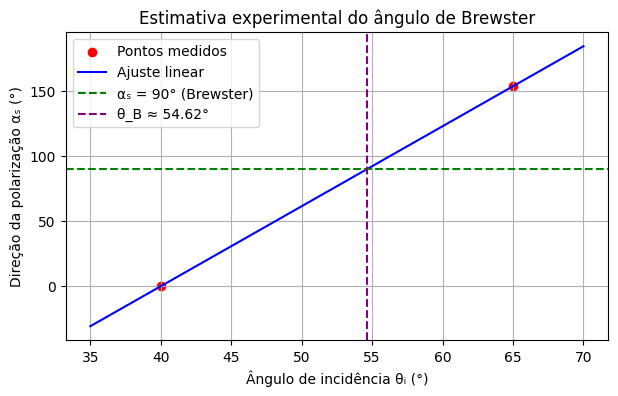

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dados experimentais
theta_i = np.array([40, 65])     # Ângulos de incidência
alpha_s = np.array([0.0, 153.9]) # Direções de polarização (α₀) medidas

# Ajuste linear
m = (alpha_s[-1] - alpha_s[0]) / (theta_i[-1] - theta_i[0])
b = alpha_s[0] - m * theta_i[0]

# Estimativa de Brewster (α_s = 90°)
theta_B_est = (90 - b) / m
print(f"Estimativa do ângulo de Brewster: θ_B ≈ {theta_B_est:.2f}°")

# Gráfico
theta_fit = np.linspace(min(theta_i)-5, max(theta_i)+5, 100)
alpha_fit = m * theta_fit + b

plt.figure(figsize=(7,4))
plt.scatter(theta_i, alpha_s, color='red', label='Pontos medidos')
plt.plot(theta_fit, alpha_fit, color='blue', label='Ajuste linear')
plt.axhline(90, color='green', linestyle='--', label='αₛ = 90° (Brewster)')
plt.axvline(theta_B_est, color='purple', linestyle='--', label=f'θ_B ≈ {theta_B_est:.2f}°')
plt.xlabel("Ângulo de incidência θᵢ (°)")
plt.ylabel("Direção da polarização αₛ (°)")
plt.title("Estimativa experimental do ângulo de Brewster")
plt.legend()
plt.grid(True)
plt.show()
